# Vietnam Portfolio Risk — risk budget, stress, and hedge economics

**Decision question.** Where does risk originate, do VaR/ES and liquidity controls pass, and when does a VN30 futures overlay reduce absolute risk without unacceptable tracking disruption?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: vietnam-portfolio-risk-stress-lab


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['data/sample/holdings_2026-09-30.csv', 'reports/coverage_audit.csv', 'reports/risk_contributions.csv', 'reports/sector_risk.csv', 'reports/liquidity.csv', 'reports/rolling_risk.csv', 'reports/var_backtest.csv', 'reports/risk_summary.json', 'data/market/snapshot_metadata.json', 'assets/risk_dashboard_preview.png', 'assets/risk_detail_preview.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,data/sample/holdings_2026-09-30.csv,True,3317
1,reports/coverage_audit.csv,True,2051
2,reports/risk_contributions.csv,True,4048
3,reports/sector_risk.csv,True,725
4,reports/liquidity.csv,True,2840
5,reports/rolling_risk.csv,True,24141
6,reports/var_backtest.csv,True,11671
7,reports/risk_summary.json,True,139166
8,data/market/snapshot_metadata.json,True,3510
9,assets/risk_dashboard_preview.png,True,172654


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `data/sample/holdings_2026-09-30.csv`

In [4]:
frame_1 = load_artifact('data/sample/holdings_2026-09-30.csv')
audit_frame(frame_1, 'data/sample/holdings_2026-09-30.csv')

#### Data-quality audit — `data/sample/holdings_2026-09-30.csv`

,metric,value
0,rows,31
1,columns,7
2,missing cells,0
3,duplicate rows,0
4,numeric columns,2


,as_of_date,ticker,company,sector,reported_weight_pct,source_id,source_page
0,2026-09-30,ACB,Asia Commercial Bank,Financials,3.8200,ssiam_september_2026_factsheet,9
1,2026-09-30,BID,Joint Stock Commercial Bank for Investment and...,Financials,0.6200,ssiam_september_2026_factsheet,9
2,2026-09-30,BSR,Binh Son Refining and Petrochemical Joint Stoc...,Energy,1.0700,ssiam_september_2026_factsheet,9
3,2026-09-30,CTG,Vietnam Joint Stock Commercial Bank for Indust...,Financials,1.2800,ssiam_september_2026_factsheet,9
4,2026-09-30,FPT,FPT Corporation,Information Technology,8.6200,ssiam_september_2026_factsheet,9
5,2026-09-30,GAS,PetroVietnam Gas Joint Stock Corporation,Utilities,0.8400,ssiam_september_2026_factsheet,9
6,2026-09-30,GVR,Vietnam Rubber Group JSC,Materials,0.4500,ssiam_september_2026_factsheet,9
7,2026-09-30,HDB,Ho Chi Minh City Development Joint Stock Comme...,Financials,4.0400,ssiam_september_2026_factsheet,9


,count,mean,std,min,50%,max
reported_weight_pct,31.0000,3.2265,2.7079,0.1700,3.0300,10.6200
source_page,31.0000,8.9677,0.1796,8.0000,9.0000,9.0000


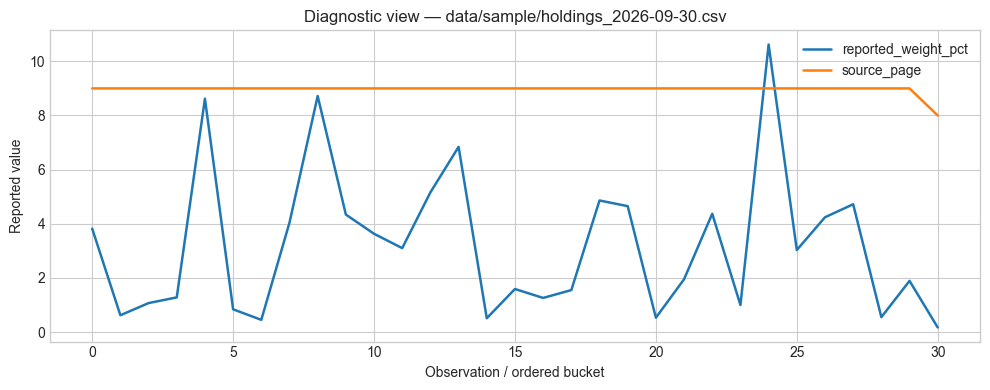

In [5]:
plot_numeric(frame_1, 'Diagnostic view — data/sample/holdings_2026-09-30.csv')

## 3. Evidence table — `reports/coverage_audit.csv`

In [6]:
frame_2 = load_artifact('reports/coverage_audit.csv')
audit_frame(frame_2, 'reports/coverage_audit.csv')

#### Data-quality audit — `reports/coverage_audit.csv`

,metric,value
0,rows,30
1,columns,9
2,missing cells,0
3,duplicate rows,0
4,numeric columns,3


,ticker,sector,first_date,last_date,raw_price_rows,usable_returns_last_500,missing_quote_days_after_listing,primary_500d_method,recent_250d_method
0,ACB,Financials,2019-01-02,2026-09-30,1926,500,5,own,own
1,BID,Financials,2019-01-02,2026-09-30,1931,500,0,own,own
2,BSR,Energy,2019-01-02,2026-09-30,1923,500,8,own,own
3,CTG,Financials,2019-01-02,2026-09-30,1931,500,0,own,own
4,FPT,Information Technology,2019-01-02,2026-09-30,1931,500,0,own,own
5,GAS,Utilities,2019-01-02,2026-09-30,1931,500,0,own,own
6,GVR,Materials,2019-01-02,2026-09-30,1925,500,6,own,own
7,HDB,Financials,2019-01-02,2026-09-30,1931,500,0,own,own


,count,mean,std,min,50%,max
raw_price_rows,30.0000,"1,801.7000",423.2279,234.0000,"1,931.0000","1,931.0000"
usable_returns_last_500,30.0000,485.9667,55.4284,233.0000,500.0000,500.0000
missing_quote_days_after_listing,30.0000,1.4667,2.8975,0.0000,0.0000,10.0000


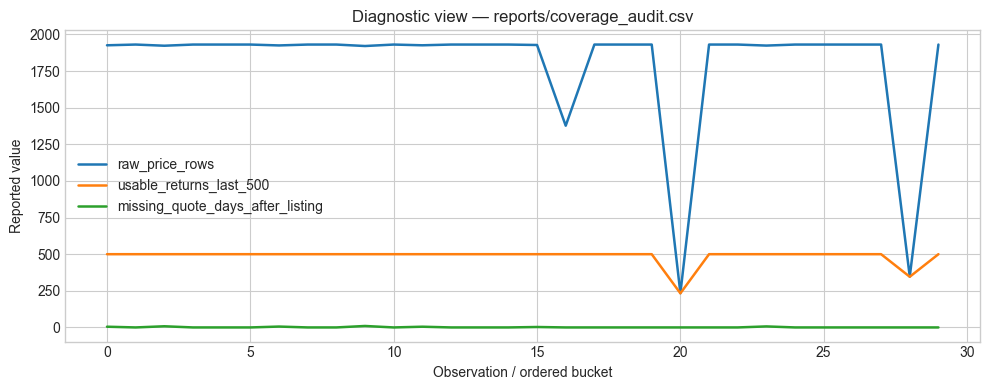

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/coverage_audit.csv')

## 4. Evidence table — `reports/risk_contributions.csv`

In [8]:
frame_3 = load_artifact('reports/risk_contributions.csv')
audit_frame(frame_3, 'reports/risk_contributions.csv')

#### Data-quality audit — `reports/risk_contributions.csv`

,metric,value
0,rows,30
1,columns,8
2,missing cells,0
3,duplicate rows,0
4,numeric columns,5


,ticker,sector,analytical_weight,component_annualised_volatility,share_of_total_volatility,marginal_annualised_volatility,model_method_500d,component_parametric_var_99
0,VIC,Real Estate,0.1062,0.0274,0.1354,0.2579,own,0.0039
1,HPG,Materials,0.0872,0.0169,0.0834,0.1935,own,0.0024
2,MWG,Consumer Discretionary,0.0684,0.0168,0.0829,0.2451,own,0.0024
3,FPT,Information Technology,0.0862,0.0159,0.0785,0.1843,own,0.0023
4,VHM,Real Estate,0.0437,0.0119,0.0587,0.2717,own,0.0017
5,VPB,Financials,0.0472,0.0114,0.0563,0.2412,own,0.0016
6,TCB,Financials,0.0465,0.0107,0.0528,0.2297,own,0.0015
7,MSN,Consumer Staples,0.0516,0.0102,0.0507,0.1986,own,0.0015


,count,mean,std,min,50%,max
analytical_weight,30.0000,0.0333,0.0269,0.0045,0.0306,0.1062
component_annualised_volatility,30.0000,0.0067,0.0063,0.0005,0.0049,0.0274
share_of_total_volatility,30.0000,0.0333,0.0311,0.0027,0.0242,0.1354
marginal_annualised_volatility,30.0000,0.1918,0.0489,0.1024,0.1919,0.2717
component_parametric_var_99,30.0000,0.0010,0.0009,0.0001,0.0007,0.0039


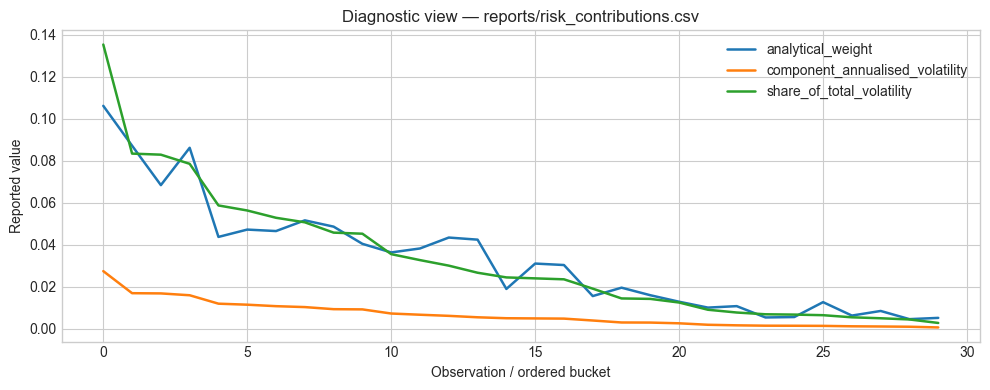

In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/risk_contributions.csv')

## 5. Evidence table — `reports/sector_risk.csv`

In [10]:
frame_4 = load_artifact('reports/sector_risk.csv')
audit_frame(frame_4, 'reports/sector_risk.csv')

#### Data-quality audit — `reports/sector_risk.csv`

,metric,value
0,rows,9
1,columns,4
2,missing cells,0
3,duplicate rows,0
4,numeric columns,3


,sector,weight,share_of_total_volatility,risk_to_weight_ratio
0,Financials,0.3983,0.3857,0.9683
1,Real Estate,0.1688,0.2185,1.2946
2,Consumer Staples,0.1301,0.1039,0.7988
3,Consumer Discretionary,0.0739,0.0896,1.2122
4,Materials,0.0917,0.0878,0.9572
5,Information Technology,0.0862,0.0785,0.9113
6,Industrials,0.0303,0.0235,0.7751
7,Energy,0.0107,0.0077,0.7156


,count,mean,std,min,50%,max
weight,9.0000,0.1109,0.1203,0.0084,0.0862,0.3983
share_of_total_volatility,9.0000,0.1111,0.1218,0.0049,0.0878,0.3857
risk_to_weight_ratio,9.0000,0.9132,0.2287,0.5855,0.9113,1.2946


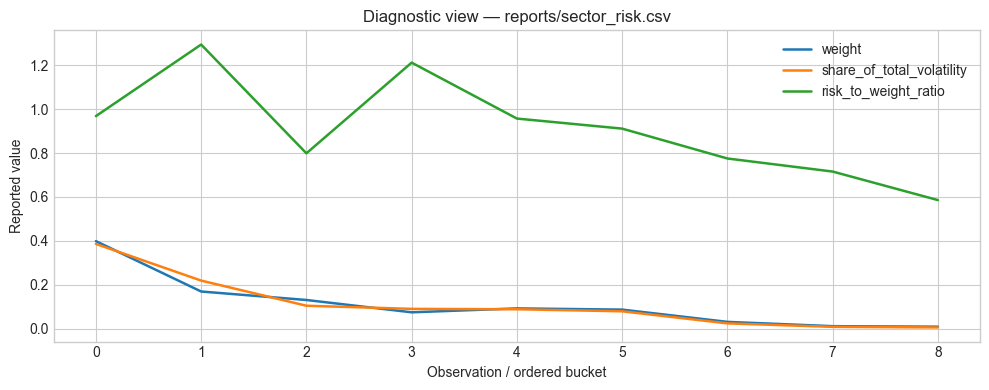

In [11]:
plot_numeric(frame_4, 'Diagnostic view — reports/sector_risk.csv')

## 6. Evidence table — `reports/liquidity.csv`

In [12]:
frame_5 = load_artifact('reports/liquidity.csv')
audit_frame(frame_5, 'reports/liquidity.csv')

#### Data-quality audit — `reports/liquidity.csv`

,metric,value
0,rows,30
1,columns,8
2,missing cells,0
3,duplicate rows,0
4,numeric columns,7


,ticker,position_vnd,median_60d_traded_value_vnd,participation_rate,days_to_exit,stress_participation_rate,stress_volume_haircut,stressed_days_to_exit
0,MCH,"3,099,380,123.9752","38,508,000,000.0000",0.2000,0.4024,0.1000,0.5000,1.6097
1,SSB,"1,259,748,050.3899","35,716,765,000.0000",0.2000,0.1764,0.1000,0.5000,0.7054
2,LPB,"4,339,132,173.5653","129,194,590,000.0000",0.2000,0.1679,0.1000,0.5000,0.6717
3,MWG,"6,838,632,273.5453","213,043,000,000.0000",0.2000,0.1605,0.1000,0.5000,0.6420
4,STB,"4,859,028,194.3611","199,467,160,000.0000",0.2000,0.1218,0.1000,0.5000,0.4872
5,FPT,"8,618,276,344.7311","382,727,185,000.0000",0.2000,0.1126,0.1000,0.5000,0.4504
6,VJC,"3,029,394,121.1758","138,507,585,000.0000",0.2000,0.1094,0.1000,0.5000,0.4374
7,VNM,"4,239,152,169.5661","198,151,685,000.0000",0.2000,0.1070,0.1000,0.5000,0.4279


,count,mean,std,min,50%,max
position_vnd,30.0000,"3,327,667,799.7734","2,692,548,532.3499","449,910,017.9964","3,064,387,122.5755","10,617,876,424.7151"
median_60d_traded_value_vnd,30.0000,"246,887,390,250.0000","202,700,020,202.2445","24,868,185,000.0000","212,242,920,000.0000","955,254,200,000.0000"
participation_rate,30.0000,0.2000,0.0000,0.2000,0.2000,0.2000
days_to_exit,30.0000,0.0859,0.0744,0.0144,0.0715,0.4024
stress_participation_rate,30.0000,0.1000,0.0000,0.1000,0.1000,0.1000
stress_volume_haircut,30.0000,0.5000,0.0000,0.5000,0.5000,0.5000
stressed_days_to_exit,30.0000,0.3436,0.2978,0.0578,0.2860,1.6097


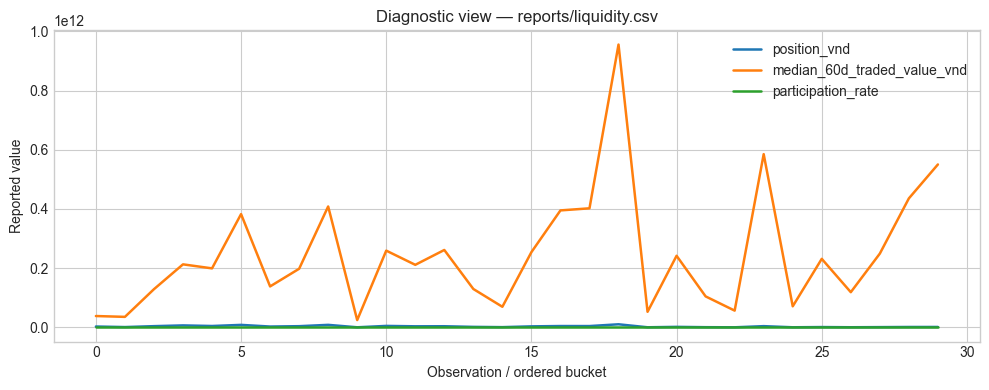

In [13]:
plot_numeric(frame_5, 'Diagnostic view — reports/liquidity.csv')

## 7. Evidence table — `reports/rolling_risk.csv`

In [14]:
frame_6 = load_artifact('reports/rolling_risk.csv')
audit_frame(frame_6, 'reports/rolling_risk.csv')

#### Data-quality audit — `reports/rolling_risk.csv`

,metric,value
0,rows,337
1,columns,4
2,missing cells,0
3,duplicate rows,0
4,numeric columns,3


,date,annualised_volatility_60d,historical_var_99_250d,drawdown
0,2020-01-03,0.1077,0.0192,-0.0598
1,2020-01-10,0.1184,0.0192,-0.0570
2,2020-01-17,0.1184,0.0192,-0.0462
3,2020-01-31,0.1539,0.0238,-0.0893
4,2020-02-07,0.1618,0.0238,-0.0619
5,2020-02-14,0.1649,0.0238,-0.0574
6,2020-02-21,0.1606,0.0238,-0.0586
7,2020-02-28,0.1841,0.0257,-0.0859


,count,mean,std,min,50%,max
annualised_volatility_60d,337.0000,0.2085,0.0752,0.0980,0.1932,0.4003
historical_var_99_250d,337.0000,0.0437,0.0108,0.0192,0.0465,0.0668
drawdown,337.0000,-0.1086,0.1043,-0.4123,-0.0653,0.0000


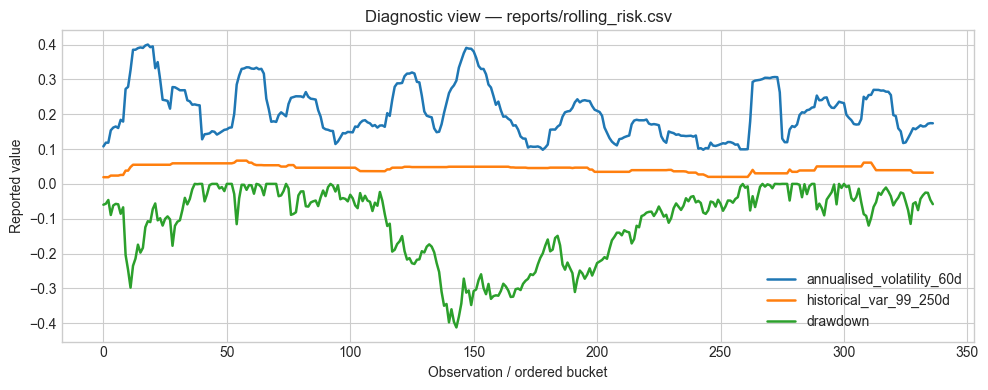

In [15]:
plot_numeric(frame_6, 'Diagnostic view — reports/rolling_risk.csv')

## 8. Evidence table — `reports/var_backtest.csv`

In [16]:
frame_7 = load_artifact('reports/var_backtest.csv')
audit_frame(frame_7, 'reports/var_backtest.csv')

#### Data-quality audit — `reports/var_backtest.csv`

,metric,value
0,rows,250
1,columns,4
2,missing cells,0
3,duplicate rows,0
4,numeric columns,3


,date,var_99,realised_loss,exception
0,2025-09-29,0.0386,0.0000,0
1,2025-09-30,0.0386,0.0000,0
2,2025-10-01,0.0386,0.0000,0
3,2025-10-02,0.0386,0.0057,0
4,2025-10-03,0.0386,0.0013,0
5,2025-10-06,0.0386,0.0000,0
6,2025-10-07,0.0386,0.0043,0
7,2025-10-08,0.0386,0.0000,0


,count,mean,std,min,50%,max
var_99,250.0000,0.0441,0.0084,0.0322,0.0394,0.0611
realised_loss,250.0000,0.0045,0.0084,0.0000,0.0001,0.0671
exception,250.0000,0.0080,0.0893,0.0000,0.0000,1.0000


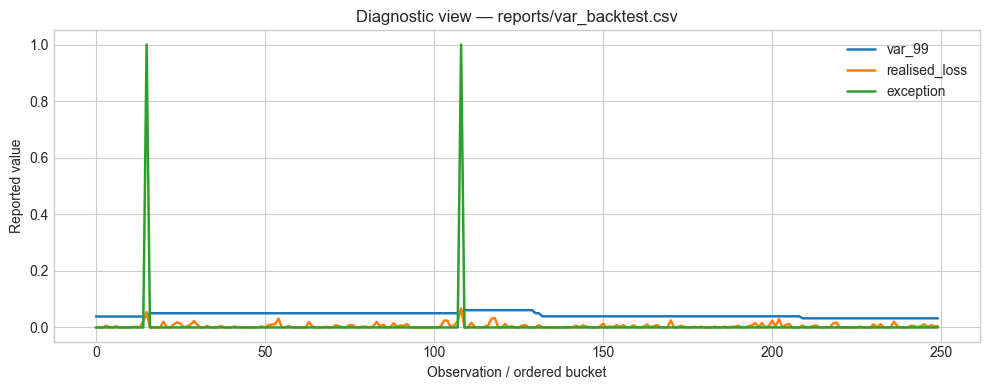

In [17]:
plot_numeric(frame_7, 'Diagnostic view — reports/var_backtest.csv')

## 9. Locked decision object — `reports/risk_summary.json`

In [18]:
payload = load_artifact('reports/risk_summary.json')
show_json(payload, 'reports/risk_summary.json')

#### reports/risk_summary.json

,field,value
0,case,"{""as_of"": ""2026-09-30"", ""portfolio"": ""FUESSV30..."
1,risk,"{""primary_500d"": {""observations"": 500, ""annual..."
2,concentration,"{""largest_name"": ""VIC"", ""largest_name_weight"":..."
3,stress,"{""worst_1d"": {""start"": ""2020-03-09"", ""end"": ""2..."
4,backtest,"{""lookback"": 250, ""evaluation_observations"": 2..."
5,hedge,"{""index_level_proxy"": 1906.81, ""contract_multi..."
6,limits,"{""breaches"": {""single_name"": false, ""sector"": ..."
7,coverage_audit,"[{""ticker"": ""ACB"", ""sector"": ""Financials"", ""fi..."
8,component_risk,"[{""ticker"": ""VIC"", ""sector"": ""Real Estate"", ""a..."
9,sector_risk,"[{""sector"": ""Financials"", ""weight"": 0.39832033..."


## 10. Locked decision object — `data/market/snapshot_metadata.json`

In [19]:
payload = load_artifact('data/market/snapshot_metadata.json')
show_json(payload, 'data/market/snapshot_metadata.json')

#### data/market/snapshot_metadata.json

,field,value
0,retrieved_at,2026-10-13T07:06:54.510297+00:00
1,start_date,2019-01-02
2,end_date,2026-09-30
3,stock_endpoint,https://api-finfo.vndirect.com.vn/v4/stock_prices
4,index_endpoint,https://api-finfo.vndirect.com.vn/v4/vnmarket_...
5,stock_rows,54051
6,benchmark_rows,1931
7,coverage,"{""ACB"": {""rows"": 1926, ""first_date"": ""2019-01-..."


## Visual evidence

![risk_dashboard_preview](../assets/risk_dashboard_preview.png)

![risk_detail_preview](../assets/risk_detail_preview.png)

## Decision

**Retain the unhedged mandate while all approved controls pass. Use the beta-0.70 futures overlay only under a tighter absolute-risk mandate and after margin-liquidity and tracking-error controls.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [20]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

The case is a frozen shadow mandate, not an ETF recommendation. Some short-history volatilities use governed proxies; liquidity and futures execution remain scenario estimates.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.